In [1]:
# Configure every external directory here before executing the notebook.
from pathlib import Path
import os
PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == 'notebooks':
    PROJECT_DIR = PROJECT_DIR.parent
RAW_DIR = Path(os.environ.get('RIDESHARE_RAW_DIR', str(PROJECT_DIR / 'data/raw/fhvhv')))
PROCESSED_DIR = Path(os.environ.get('RIDESHARE_PROCESSED_DIR', str(PROJECT_DIR / 'data/processed')))
ZONE_DIR = Path(os.environ.get('RIDESHARE_ZONE_DIR', str(PROJECT_DIR / 'data/reference/taxi_zones')))
WEATHER_DIR = Path(os.environ.get('RIDESHARE_WEATHER_DIR', str(PROJECT_DIR / 'data/reference/weather_hourly')))
ANALYSIS_DIR = PROJECT_DIR / 'outputs/demand_analysis'
# Spark users: configure JAVA_HOME and, on Windows when required, HADOOP_HOME externally.


# Study inputs: HVFHV begins in February 2019; 2020 is intentionally excluded.
SOURCE_YEARS = [2019, 2021, 2022, 2023, 2024, 2025]
INVENTORY_DIR = PROJECT_DIR / 'outputs/source_inventory'


# 01 Source data inventory and schema review

## Research question and scope
Which monthly HVFHV source files are available, how large are they, and which fields vary across years? This notebook documents **71 source months**: February–December 2019 and all months of 2021–2025. It does not read 2020. The January 2026 forecast-test source is acquired separately for the established held-out evaluation.

## How to use this notebook
Set the first-cell directories, obtain the monthly Parquet files from the TLC source below, then run the remaining cells in order. This notebook reads Parquet **metadata**, not every raw trip. Its row counts come from file footers; it does not claim a complete null/duplicate audit. Notebook 02 applies row-level cleaning and aggregate checks.

Official data source: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page

Monthly filename pattern: `fhvhv_tripdata_YYYY-MM.parquet`.


In [2]:
import calendar
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display

# Keep generated summary tables outside the versioned source-data directories.
INVENTORY_DIR.mkdir(parents=True, exist_ok=True)


## 1 Check the requested monthly files
Build the explicit source manifest before any aggregation. A missing file stops the notebook; missing months are not interpreted as zero trips.


In [3]:
# Enumerate only the intended months, using the provider's source filenames.
months = [(year, month) for year in SOURCE_YEARS for month in range(1, 13)
          if (year, month) != (2019, 1)]
assert len(months) == 71 and all(year != 2020 for year, _ in months)
missing = [f'fhvhv_tripdata_{year}-{month:02d}.parquet' for year, month in months
           if not (RAW_DIR / f'fhvhv_tripdata_{year}-{month:02d}.parquet').is_file()]
assert not missing, f'Download these source files first: {missing}'
print(f'All {len(months)} requested monthly source files are present.')


All 71 requested monthly source files are present.


## 2 Inspect counts and schemas without loading whole files
The footer inventory is inexpensive relative to scanning raw records. The schema comparison identifies fields that need explicit handling in preparation. No raw trip rows are published here.


In [4]:
records, schema_rows = [], []
for year, month in months:
    path = RAW_DIR / f'fhvhv_tripdata_{year}-{month:02d}.parquet'
    parquet = pq.ParquetFile(path)
    # Footer counts describe rows supplied by the provider, before cleaning.
    records.append(dict(year=year, month=month, source_file=path.name,
                        raw_rows=parquet.metadata.num_rows,
                        file_gb=path.stat().st_size / 1e9,
                        columns=len(parquet.schema_arrow.names)))
    for field in parquet.schema_arrow:
        schema_rows.append(dict(year=year, month=month, field=field.name,
                                data_type=str(field.type)))
inventory = pd.DataFrame(records)
schema = pd.DataFrame(schema_rows)
display(inventory.head(12))
display(inventory.groupby('year').agg(months=('month', 'count'),
        raw_rows=('raw_rows', 'sum'), file_gb=('file_gb', 'sum')))


,year,month,source_file,raw_rows,file_gb,columns
0,2019,2,fhvhv_tripdata_2019-02.parquet,20159102,0.513055,24
1,2019,3,fhvhv_tripdata_2019-03.parquet,23864598,0.610854,24
2,2019,4,fhvhv_tripdata_2019-04.parquet,21734822,0.559657,24
3,2019,5,fhvhv_tripdata_2019-05.parquet,22329247,0.570821,24
4,2019,6,fhvhv_tripdata_2019-06.parquet,21001990,0.536192,24
5,2019,7,fhvhv_tripdata_2019-07.parquet,20303312,0.516008,24
6,2019,8,fhvhv_tripdata_2019-08.parquet,20126113,0.501436,24
7,2019,9,fhvhv_tripdata_2019-09.parquet,20069321,0.515945,24
8,2019,10,fhvhv_tripdata_2019-10.parquet,21162290,0.549370,24
9,2019,11,fhvhv_tripdata_2019-11.parquet,21635568,0.561012,24


,months,raw_rows,file_gb
year,,,
2019,11,234630264,6.010999
2021,12,174596652,4.553804
2022,12,212416083,5.436647
2023,12,232490020,5.820780
2024,12,239470448,5.776047
2025,12,243589684,5.959294


## 3 Compare field availability
Presence is a schema property, not proof that a field has non-null or valid values. Notebook 02 derives duration/speed and applies the selected cleaning conditions.


In [5]:
# Each cell counts the number of monthly schemas containing a field.
availability = schema.groupby(['field', 'year']).size().unstack('year', fill_value=0)
display(availability)
inventory.to_csv(INVENTORY_DIR / 'source_inventory.csv', index=False)
availability.to_csv(INVENTORY_DIR / 'source_field_availability.csv')


year,2019,2021,2022,2023,2024,2025
field,,,,,,
DOLocationID,11,12,12,12,12,12
PULocationID,11,12,12,12,12,12
access_a_ride_flag,11,12,12,12,12,12
airport_fee,11,12,12,12,12,12
base_passenger_fare,11,12,12,12,12,12
bcf,11,12,12,12,12,12
cbd_congestion_fee,0,0,0,0,0,12
congestion_surcharge,11,12,12,12,12,12
dispatching_base_num,11,12,12,12,12,12


## 4 Plot the source series
Gaps separate years that were deliberately not selected. These are raw source counts and should not be confused with the cleaned pickup totals in notebooks 03–05.


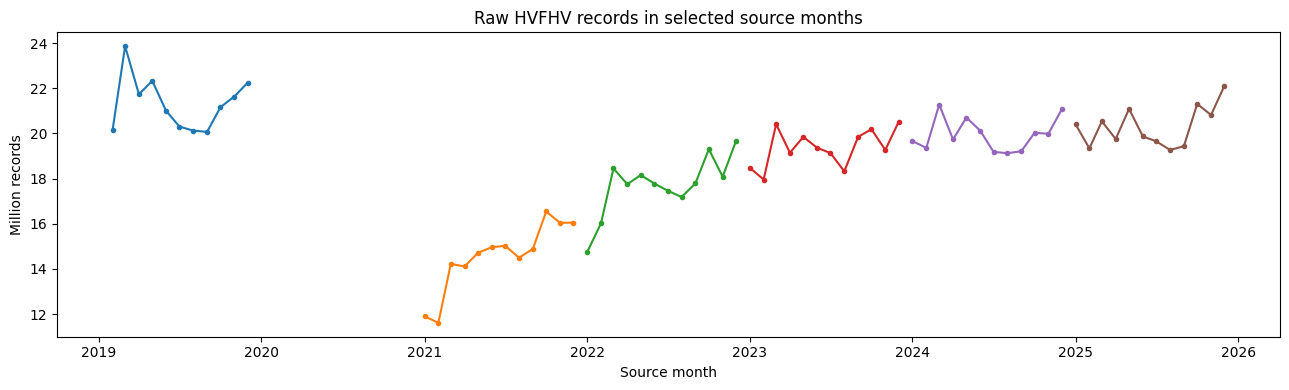

In [6]:
fig, ax = plt.subplots(figsize=(13, 4))
for year, group in inventory.groupby('year'):
    dates = pd.to_datetime(dict(year=group.year, month=group.month, day=1))
    ax.plot(dates, group.raw_rows / 1e6, marker='o', markersize=3)
ax.set(title='Raw HVFHV records in selected source months',
       xlabel='Source month', ylabel='Million records')
fig.tight_layout()
fig.savefig(INVENTORY_DIR / '01_source_monthly_counts.png', dpi=150)
plt.show()


## Findings and next step
The executed inventory below documents file availability and metadata only. Raw data remain outside GitHub. Next, run the unexecuted notebook 02 in a **fresh output directory** to create and validate cleaned pickup, dropoff and OD hourly aggregates. Descriptive research in notebooks 03–05 uses 2021–2025 only.
